## Feature Engineering

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df_raw = pd.read_csv("data.csv")

df_raw.head()

,gamesPlayed,gamesStarted,minutesPlayed,twoPointersMade,twoPointersAttempted,threePointersMade,threePointersAttempted,offensiveRebounds,defensiveRebounds,totalRebounds,...,steals,turnovers,blocks,freeThrowsMade,freeThrowsAttempted,foulsDrawn,code,name,season,position
0,26.0,0.0,8.480128,0.1,0.4,0.1,0.9,0.2,0.3,0.5,...,0.2,0.4,0.1,0.3,0.4,0.4,007265,"KURUCS, ARTURS",2021,1
1,31.0,3.0,6.978495,0.2,0.5,0.8,2.2,0.0,0.4,0.4,...,0.1,0.2,0.0,0.0,0.1,0.4,004508,"OBST, ANDREAS",2021,1
2,25.0,20.0,10.805333,0.4,0.8,0.6,1.4,0.2,0.6,0.7,...,0.4,0.3,0.1,0.0,0.0,0.1,007338,"UZINSKII, DMITRII",2021,2
3,23.0,2.0,7.260870,0.7,1.4,0.1,0.5,0.2,0.5,0.7,...,0.3,0.7,0.0,0.2,0.3,0.6,011220,"ZIV, IFTAH",2021,1
4,26.0,3.0,12.396154,0.6,1.5,0.3,1.4,0.2,0.4,0.7,...,0.3,0.6,0.1,0.6,0.7,0.8,011204,"GRANT, JERIAN",2021,1


In [3]:
df_filtered = df_raw[(df_raw["minutesPlayed"] >= 10) & (df_raw["gamesPlayed"] >= 10)].reset_index()
print(f"Dropped {len(df_raw) - len(df_filtered)} rows with not enough games/minutes played. Now {len(df_filtered)}.")

Dropped 46 rows with not enough games/minutes played. Now 927.


In [4]:
df = pd.DataFrame()

df["POS"] = df_filtered["position"]
df["3PAr"] = df_filtered["threePointersAttempted"] / ( df_filtered["twoPointersAttempted"] + df_filtered["threePointersAttempted"] )
df["3Pr"] = df_filtered["threePointersMade"] / df_filtered["threePointersAttempted"]
df["2Pr"] = df_filtered["twoPointersMade"] / df_filtered["twoPointersAttempted"]
df["2P"] = df_filtered["twoPointersMade"] / df_filtered["minutesPlayed"] * 40
df["FD"] = df_filtered["foulsDrawn"] / df_filtered["minutesPlayed"] * 40
df["FTr"] = df_filtered["freeThrowsAttempted"] / ( df_filtered["twoPointersAttempted"] + df_filtered["threePointersAttempted"] )
df["AST"] = df_filtered["assists"] / df_filtered["minutesPlayed"] * 40
df["TR"] = df_filtered["totalRebounds"] / df_filtered["minutesPlayed"] * 40
df["BLK"] = df_filtered["blocks"] / df_filtered["minutesPlayed"] * 40
df["AST/TO"] = df_filtered["assists"] / ( df_filtered["turnovers"] + 1) # Laplace smoothing to avoid division by zero


# split df into labels y and features X
y = df["POS"]
X = df.drop("POS", axis=1)

X.head()

,3PAr,3Pr,2Pr,2P,FD,FTr,AST,TR,BLK,AST/TO
0,0.636364,0.428571,0.500000,1.480750,0.370188,0.000000,1.110563,2.591313,0.370188,0.230769
1,0.482759,0.214286,0.400000,1.936084,2.581446,0.241379,2.258765,2.258765,0.322681,0.437500
2,0.750000,0.333333,0.333333,0.899568,1.499279,0.027778,1.799135,2.698703,0.000000,0.500000
3,0.612903,0.210526,0.500000,2.038348,1.698623,0.129032,0.679449,7.473942,0.000000,0.133333
4,0.666667,0.285714,0.571429,2.983179,1.118692,0.119048,1.118692,1.118692,0.000000,0.230769


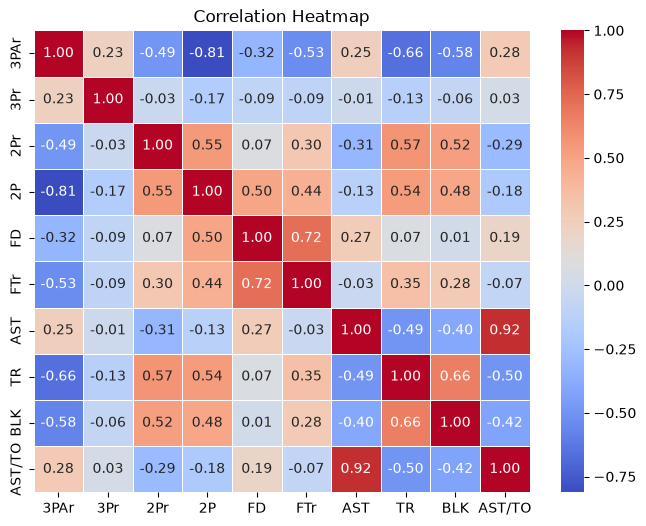

In [5]:
corr_matrix = X.corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

## Exploratory Data Analysis

In [6]:
df.describe()

,POS,3PAr,3Pr,2Pr,2P,FD,FTr,AST,TR,BLK,AST/TO
count,927.000000,927.000000,844.000000,927.000000,927.000000,927.000000,927.000000,927.000000,927.000000,927.000000,927.000000
mean,1.800431,0.400913,0.350266,0.540476,3.968762,3.871714,0.286889,3.395674,6.104107,0.491872,0.756314
std,0.760868,0.212097,0.100491,0.086136,1.845655,1.638721,0.139005,2.294183,2.477440,0.591048,0.439635
min,1.000000,0.000000,0.000000,0.272727,0.259799,0.370188,0.000000,0.000000,1.118692,0.000000,0.000000
25%,1.000000,0.280244,0.312500,0.488889,2.592084,2.646555,0.185185,1.699085,4.089884,0.129503,0.415230
50%,2.000000,0.435897,0.357143,0.538462,3.776925,3.637466,0.266667,2.605923,5.713599,0.286164,0.666667
75%,2.000000,0.546165,0.400000,0.596633,5.054821,4.859406,0.370370,4.559224,7.824645,0.667363,1.000000
max,3.000000,0.928571,1.000000,0.888889,10.044843,10.059677,0.956522,12.312549,13.891417,3.519355,2.280000


In [7]:
y.value_counts()

POS
1    379
2    354
3    194
Name: count, dtype: int64

It seems that we need to balance the classes as there are twice as many guards than centers.